# 04 · Clustering the reviews: k-means (with a hierarchical-clustering cross-check)

**Why clustering, not KNN.** OpinRank has no class label (no star rating), so there is nothing
for a supervised KNN classifier to learn. The question asks for "KNN classification / k-means
clustering, whichever is relevant". Unsupervised k-means fits: it finds the *kinds* of review
that exist.

**Representation (transformation)**
1. TF-IDF of the cleaned text: English stop-words removed, terms in at least 20 reviews and at
   most 40 % of reviews, sublinear tf. Rows are L2-normalised.
2. TruncatedSVD (LSA) to 100 dimensions: dimensionality reduction, which removes noise
   and synonymy.
3. Rows re-normalised to unit length. For unit vectors ‖a − b‖² = 2 − 2·cos(a, b), so
   Euclidean k-means groups reviews by **cosine** similarity, the usual text measure.

Each domain is clustered separately. Clustering cars and hotels together would only split
them apart, which is trivial.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             silhouette_score)
from sklearn.preprocessing import normalize

import plots as P

warnings.filterwarnings("ignore", category=FutureWarning)
P.set_style()
CLEAN = Path(r"C:\data\ASBD_exam\clean")
TABLES = Path("../outputs/tables")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
SEED = 42

df = pd.read_parquet(CLEAN / "reviews_model.parquet")
print(df["domain"].value_counts().to_dict())

{'hotel': 218298, 'car': 40845}


In [2]:
def represent(texts, n_comp=100):
    """TF-IDF -> TruncatedSVD (LSA) -> unit-length rows. Returns (vectorizer, tfidf, svd, Z)."""
    vec = TfidfVectorizer(stop_words="english", min_df=20, max_df=0.4, sublinear_tf=True,
                          token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b", dtype=np.float32)
    X = vec.fit_transform(texts)
    svd = TruncatedSVD(n_components=n_comp, random_state=SEED)
    Z = normalize(svd.fit_transform(X)).astype(np.float32)
    return vec, X, svd, Z


REP = {}
for dom in ["hotel", "car"]:
    t0 = time.time()
    d = df[df["domain"] == dom].reset_index(drop=True)
    vec, X, svd, Z = represent(d["text"])
    REP[dom] = dict(d=d, vec=vec, X=X, svd=svd, Z=Z)
    print(f"{dom}: TF-IDF {X.shape[0]:,} x {X.shape[1]:,} ({X.nnz / X.shape[0]:.0f} non-zeros per review), "
          f"SVD-100 explains {svd.explained_variance_ratio_.sum():.1%} of variance, {time.time() - t0:.0f}s")

hotel: TF-IDF 218,298 x 17,562 (62 non-zeros per review), SVD-100 explains 12.7% of variance, 43s


car: TF-IDF 40,845 x 4,861 (33 non-zeros per review), SVD-100 explains 17.7% of variance, 5s


## Choosing K: elbow (SSE) and silhouette
k-means is run for K = 2…12 on a random sample of 30,000 reviews, 4 restarts each, recording:
* the **SSE** (inertia), which always falls as K grows, so look for the elbow;
* the **silhouette** on 8,000 points (−1…1, higher = tighter and better-separated clusters).

The elbow is located objectively with the "knee" rule: the K whose (normalised) SSE point lies
farthest from the straight line joining the first and last points.

hotel knee at K = 6
           SSE  silhouette  davies_bouldin   knee
K                                                
2   23298.9219      0.0214          5.8451  False
3   22887.7871      0.0202          4.9724  False
4   22499.9395      0.0232          4.8972  False
5   22229.3223      0.0270          5.2265  False
6   21990.9785      0.0310          4.9613   True
7   21775.1055      0.0276          4.8170  False
8   21586.1855      0.0288          4.9366  False
9   21421.3477      0.0296          4.6731  False
10  21284.2246      0.0286          4.6058  False
11  21154.4082      0.0284          4.5876  False
12  21027.8984      0.0304          4.5958  False 



car knee at K = 7
           SSE  silhouette  davies_bouldin   knee
K                                                
2   24955.2773      0.0177          6.8667  False
3   24552.9551      0.0175          5.9449  False
4   24265.2070      0.0188          6.0740  False
5   23934.5605      0.0230          5.4934  False
6   23707.8691      0.0227          5.3073  False
7   23486.2949      0.0253          5.2729   True
8   23295.0039      0.0251          5.1030  False
9   23135.7812      0.0254          4.9865  False
10  22974.3242      0.0268          4.9379  False
11  22835.6895      0.0273          4.8753  False
12  22749.0469      0.0274          4.8517  False 



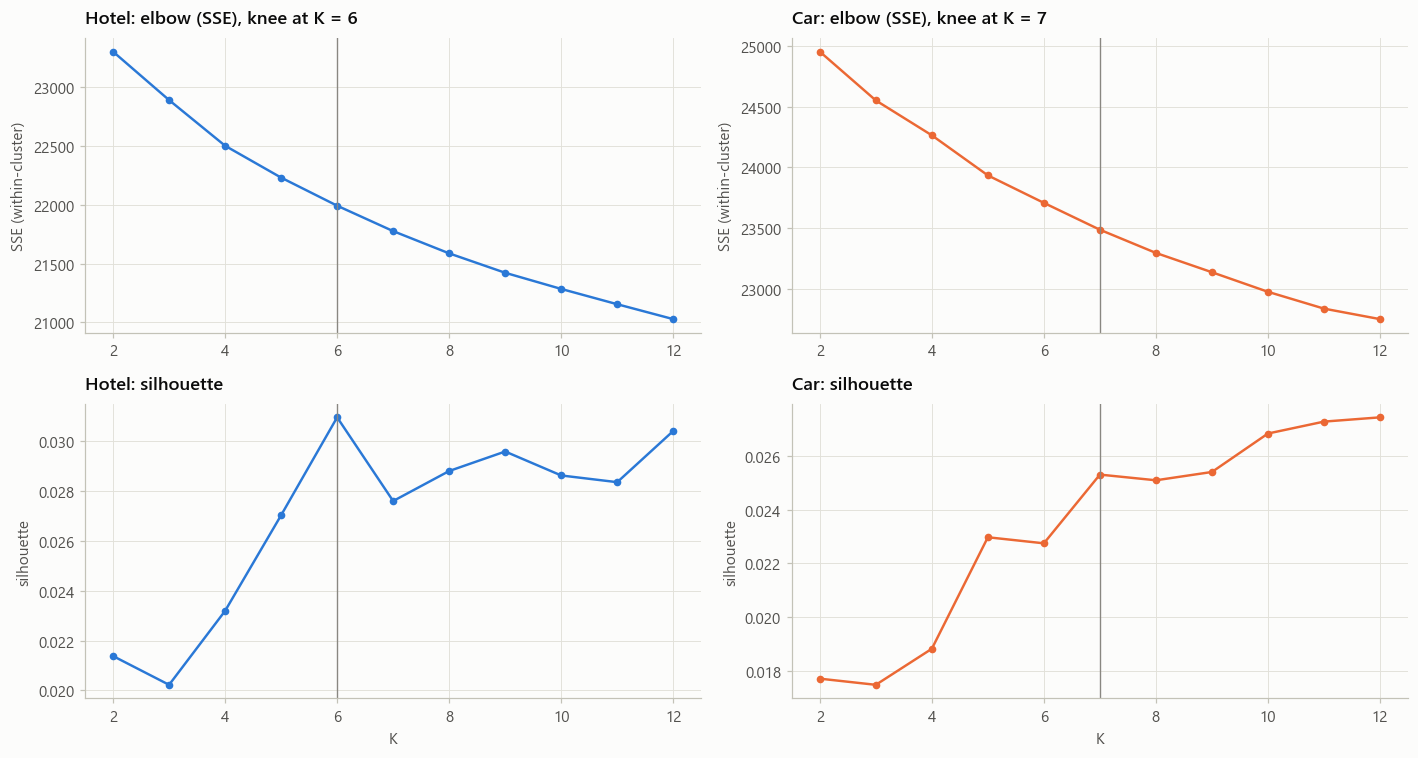

In [3]:
def knee(ks, sse):
    x = (np.asarray(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.asarray(sse) - sse[-1]) / (sse[0] - sse[-1])
    return ks[int(np.argmax(np.abs(1 - x - y) / np.sqrt(2)))]


KS = list(range(2, 13))
SEL = {}
rng = np.random.default_rng(SEED)
for dom in REP:
    Z = REP[dom]["Z"]
    idx = rng.choice(len(Z), size=min(30000, len(Z)), replace=False)
    sil_idx = idx[:8000]
    rows = []
    for k in KS:
        km = KMeans(n_clusters=k, n_init=4, random_state=SEED).fit(Z[idx])
        lab = km.predict(Z[sil_idx])
        rows.append(dict(K=k, SSE=km.inertia_, silhouette=silhouette_score(Z[sil_idx], lab),
                         davies_bouldin=davies_bouldin_score(Z[sil_idx], lab)))
    SEL[dom] = pd.DataFrame(rows).set_index("K")
    SEL[dom]["knee"] = SEL[dom].index == knee(KS, SEL[dom]["SSE"].values)
    print(dom, "knee at K =", knee(KS, SEL[dom]["SSE"].values))
    print(SEL[dom].round(4).to_string(), "\n")

fig, axs = plt.subplots(2, 2, figsize=(13, 7))
for col, dom in enumerate(REP):
    s, c = SEL[dom], P.DOMAIN[dom]
    k_star = int(s.index[s["knee"]][0])
    axs[0, col].plot(s.index, s["SSE"], color=c, marker="o", ms=4)
    axs[0, col].axvline(k_star, color=P.MUTED, lw=0.9)
    axs[0, col].set_title(f"{dom.title()}: elbow (SSE), knee at K = {k_star}")
    axs[0, col].set_ylabel("SSE (within-cluster)")
    axs[1, col].plot(s.index, s["silhouette"], color=c, marker="o", ms=4)
    axs[1, col].axvline(k_star, color=P.MUTED, lw=0.9)
    axs[1, col].set_title(f"{dom.title()}: silhouette")
    axs[1, col].set_ylabel("silhouette")
    axs[1, col].set_xlabel("K")
fig.tight_layout()
P.save(fig, "k01_elbow_silhouette")
plt.show()

**Inferences (choosing K)**
* The SSE curve bends gently. The knee rule puts the elbow at **K = 6 for hotels** and
  **K = 7 for cars**.
* For hotels the silhouette **peaks at K = 6** (0.031), agreeing with the knee. For cars it
  keeps creeping up to K = 12, so K = 7 is the knee's compromise between fit and interpretability.
* Silhouette values are low (0.02–0.03) for every K. That is normal for text in 100 dimensions:
  reviews mix topics, so the clusters overlap and are best read as dominant *themes*, not
  sharply separated groups.

## Final k-means on all reviews and cluster description
Fit with K at the knee (10 restarts) on **all** reviews of the domain. Each cluster is described by:
* its **top TF-IDF terms**, the if-then style "rule" that defines it;
* its mean sentiment and length;
* its city or make mix;
* how much more or less than average it mentions each aspect.

In [4]:
def describe_clusters(dom, k):
    R = REP[dom]
    d, X, Z, vec = R["d"], R["X"], R["Z"], R["vec"]
    t0 = time.time()
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    lab = km.labels_
    d = d.assign(cluster=lab)
    terms = np.array(vec.get_feature_names_out())
    rows = []
    group = "city_name" if dom == "hotel" else "make"
    for c in range(k):
        m = lab == c
        centroid = np.asarray(X[m].mean(axis=0)).ravel()
        top = terms[np.argsort(centroid)[::-1][:10]]
        mix = d.loc[m, group].value_counts(normalize=True)
        rows.append(dict(cluster=c, size=int(m.sum()), share=m.mean(), top_terms=", ".join(top),
                         mean_sentiment=d.loc[m, "sentiment"].mean(), neg_share=(d.loc[m, "sent_class"] == "neg").mean(),
                         median_words=d.loc[m, "word_count"].median(),
                         top_group=f"{mix.index[0]} ({mix.iloc[0]:.0%})"))
    prof = pd.DataFrame(rows).set_index("cluster")
    sample = np.random.default_rng(SEED).choice(len(Z), 10000, replace=False)
    metrics = dict(K=k, SSE=km.inertia_, silhouette=silhouette_score(Z[sample], lab[sample]),
                   davies_bouldin=davies_bouldin_score(Z[sample], lab[sample]),
                   calinski_harabasz=calinski_harabasz_score(Z[sample], lab[sample]), seconds=time.time() - t0)
    return km, d, prof, metrics


KM = {}
for dom in REP:
    k = int(SEL[dom].index[SEL[dom]["knee"]][0])
    km, d, prof, metrics = describe_clusters(dom, k)
    KM[dom] = dict(km=km, d=d, prof=prof, metrics=metrics)
    print(f"{dom}: final k-means, K = {k}:", {m: round(v, 4) for m, v in metrics.items()})
KM["hotel"]["prof"].round(3)

hotel: final k-means, K = 6: {'K': 6, 'SSE': 160112.5781, 'silhouette': 0.03, 'davies_bouldin': 4.9871, 'calinski_harabasz': 175.8827, 'seconds': 18.4303}


car: final k-means, K = 7: {'K': 7, 'SSE': 31980.6621, 'silhouette': 0.0261, 'davies_bouldin': 5.2774, 'calinski_harabasz': 139.9477, 'seconds': 9.3994}


,size,share,top_terms,mean_sentiment,neg_share,median_words,top_group
cluster,,,,,,,
0,17379,0.080,"strip, vegas, casino, pool, las, nice, time, place, clean, just",0.270,0.035,175.0,Las Vegas (99%)
1,30959,0.142,"new, york, square, times, nyc, subway, clean, central, just, small",0.323,0.014,150.0,New York (91%)
2,14957,0.069,"san, francisco, union, car, square, cable, wharf, parking, street, clean",0.312,0.023,148.0,San Francisco (97%)
3,36897,0.169,"london, tube, station, breakfast, clean, walk, small, nice, just, night",0.301,0.024,145.0,London (97%)
4,67823,0.311,"service, nice, clean, excellent, friendly, breakfast, helpful, comfortable, food, really",0.359,0.025,107.0,London (19%)
5,50283,0.230,"night, did, told, bed, desk, like, just, didn, got, bathroom",0.059,0.257,207.0,London (37%)


In [5]:
KM["car"]["prof"].round(3)

,size,share,top_terms,mean_sentiment,neg_share,median_words,top_group
cluster,,,,,,,
0,6539,0.160,"mpg, highway, mileage, miles, city, gas, driving, great, getting, drive",0.222,0.057,96.0,Toyota (18%)
1,2925,0.072,"bmw, lexus, acura, audi, mercedes, series, luxury, great, infiniti, performance",0.264,0.038,98.0,BMW (14%)
2,2682,0.066,"truck, great, like, power, cab, love, ford, trucks, better, ride",0.246,0.061,87.0,Toyota (22%)
3,5154,0.126,"fun, drive, great, love, like, gas, just, good, driving, comfortable",0.352,0.016,75.0,Toyota (9%)
4,8684,0.213,"seats, great, interior, good, like, seat, comfortable, ride, room, power",0.271,0.054,101.0,Toyota (12%)
5,3864,0.095,"dealer, problem, miles, problems, replaced, times, dealership, new, service, noise",-0.021,0.433,108.0,Honda (9%)
6,10997,0.269,"love, great, vehicle, new, just, honda, like, best, price, suv",0.297,0.034,80.0,Honda (11%)


**Inferences: the clusters as if-then descriptions**

| Hotel cluster | Share | IF the review's top terms are… | THEN the cluster is… | Mean sentiment / % negative |
|---|---|---|---|---|
| 0 | 8 % | strip, vegas, casino, pool | **Las Vegas resort** (99 % Las Vegas) | 0.27 / 3.5 % |
| 1 | 14 % | new york, square, times, subway | **New York city break** (91 % New York) | 0.32 / 1.4 % |
| 2 | 7 % | san francisco, union square, cable car, wharf, parking | **San Francisco** (97 %) | 0.31 / 2.3 % |
| 3 | 17 % | london, tube, station, breakfast | **London** (97 %) | 0.30 / 2.4 % |
| 4 | 31 % | service, nice, clean, excellent, friendly, helpful | **short generic praise** (any city; shortest, median 107 words) | **0.36** / 2.5 % |
| 5 | 23 % | night, told, bed, desk, didn't, got, bathroom | **complaint narrative** (longest, median 207 words) | **0.06 / 25.7 %** |

* Two kinds of structure emerge without any labels. Four clusters are **geographic**, held
  together by landmarks and local transport (tube, subway, cable car, strip). Two are
  **attitudinal**: brief praise vs long stories of what went wrong. The complaint cluster
  holds 23 % of the reviews but most of the negative ones (25.7 % negative vs 7.8 % overall).

| Car cluster | Share | Top terms | Theme | % negative |
|---|---|---|---|---|
| 0 | 16 % | mpg, highway, mileage, gas | fuel economy | 5.7 % |
| 1 | 7 % | bmw, lexus, acura, audi, luxury | luxury brands / performance | 3.8 % |
| 2 | 7 % | truck, power, cab, ford | pickup trucks | 6.1 % |
| 3 | 13 % | fun, drive, love | fun to drive (most positive, shortest) | 1.6 % |
| 4 | 21 % | seats, interior, comfortable, ride | cabin and comfort | 5.4 % |
| 5 | 9 % | dealer, problem, replaced, dealership, service | **problems and the dealer** | **43.3 %** |
| 6 | 27 % | love, great, vehicle, best, price, suv | general satisfaction / value | 3.4 % |

* Car cluster 5 (dealer + problems, 43 % negative, mean sentiment below 0) is the same finding
  as the association rule {dealer, reliability} ⇒ negative (lift 4.2) in notebook 03. Two
  different techniques arrive at the same conclusion.

### Cluster × aspect emphasis (supporting heatmap)
Each cell is log2[(share of the cluster's reviews that mention the aspect) ÷ (domain average)].
0 = average, +1 = twice as often, −1 = half as often. This shows what each cluster is about,
independent of the vocabulary.

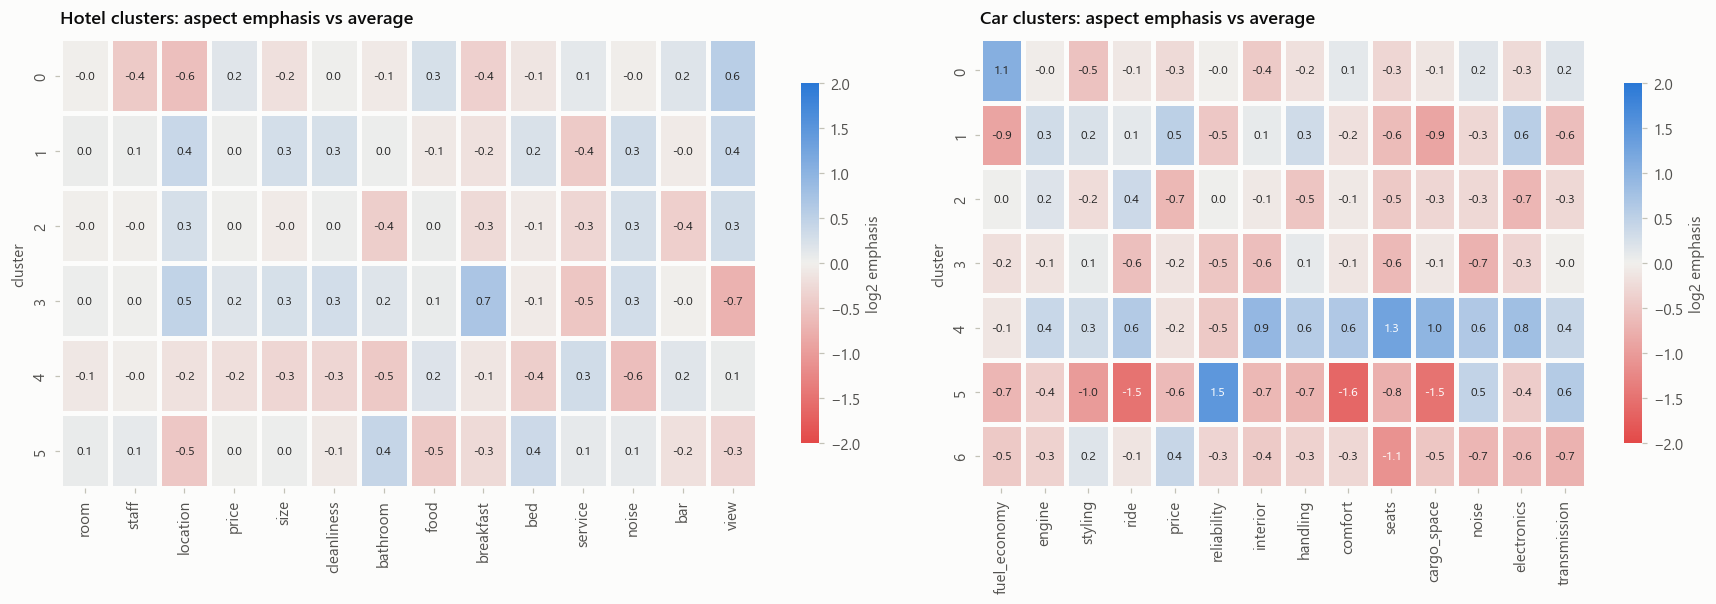

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
EMPH = {}
for ax, dom in zip(axs, ["hotel", "car"]):
    d = KM[dom]["d"]
    ex = d[["cluster", "aspects"]].explode("aspects").dropna().reset_index(drop=True)
    ct = pd.crosstab(ex["cluster"], ex["aspects"]).div(d["cluster"].value_counts().sort_index(), axis=0)
    overall = ex["aspects"].value_counts() / len(d)
    top_aspects = overall.index[:14]
    emph = np.log2(ct[top_aspects] / overall[top_aspects])
    EMPH[dom] = emph
    import seaborn as sns
    sns.heatmap(emph, cmap=P.DIVERGING, center=0, vmin=-2, vmax=2, annot=True, fmt=".1f", linewidths=2,
                linecolor=P.SURFACE, cbar_kws=dict(label="log2 emphasis", shrink=0.8), annot_kws=dict(fontsize=8), ax=ax)
    ax.set_title(f"{dom.title()} clusters: aspect emphasis vs average")
    ax.set_xlabel("")
    ax.set_ylabel("cluster")
fig.tight_layout()
P.save(fig, "k02_cluster_aspect_heatmap")
plt.show()

**Inferences (aspect emphasis)**
* The aspect profiles confirm the text-based labels. The London cluster over-mentions
  *breakfast* (+0.7) and *location*. The Las Vegas cluster talks about *view* (+0.6) and much less
  about *location* and *staff*. The complaint cluster over-mentions *bathroom* and *bed* (+0.4)
  and rarely praises *location* or *food*.
* Car cluster 5 is dominated by **reliability (+1.5, almost 3× average)**, transmission and
  noise, and almost never mentions comfort or ride (−1.5): a list of faults. Cluster 4 is the
  cabin cluster (seats +1.3, cargo space +1.0, interior +0.9).

### The clusters in 2-D (first two SVD components)
One panel per cluster: that cluster in colour over all points in grey. This is easier to read
than K overlapping colours.

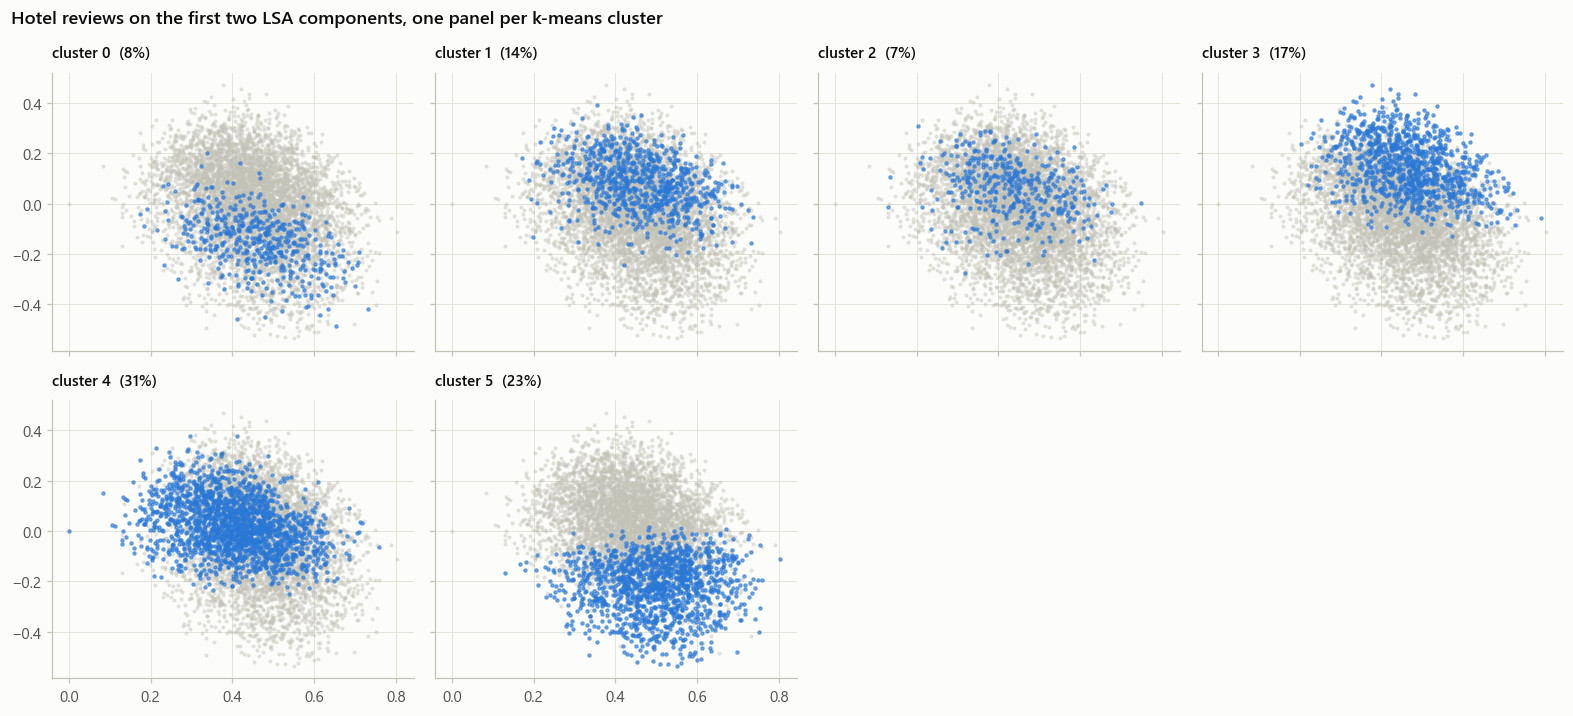

In [7]:
for dom in ["hotel"]:
    d, Z = KM[dom]["d"], REP[dom]["Z"]
    k = KM[dom]["metrics"]["K"]
    s = np.random.default_rng(SEED).choice(len(Z), 6000, replace=False)
    xy = Z[s, :2]
    ncol = min(k, 4)
    nrow = int(np.ceil(k / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.3 * nrow), sharex=True, sharey=True)
    for c, ax in zip(range(k), np.ravel(axs)):
        m = d["cluster"].values[s] == c
        ax.scatter(xy[~m, 0], xy[~m, 1], s=3, color=P.OTHER, alpha=0.35, rasterized=True)
        ax.scatter(xy[m, 0], xy[m, 1], s=4, color=P.DOMAIN[dom], alpha=0.6, rasterized=True)
        ax.set_title(f"cluster {c}  ({m.mean():.0%})", fontsize=10)
    for ax in np.ravel(axs)[k:]:
        ax.axis("off")
    fig.suptitle(f"{dom.title()} reviews on the first two LSA components, one panel per k-means cluster",
                 x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.tight_layout()
    P.save(fig, "k03_cluster_svd_panels")
    plt.show()

## Hierarchical (agglomerative) clustering and the dendrogram
Agglomerative clustering with **Ward linkage** (merges the pair of clusters that least increases
the within-cluster SSE, so it is comparable with k-means). It runs on a **stratified sample of
300 hotel reviews** (equal share from every k-means cluster) because it needs the O(n²)
distance matrix. The **K-cluster lifetime** rule (the distance range over which
exactly K clusters exist) gives a second, independent opinion on K. The adjusted Rand index
(ARI) measures how well the dendrogram cut agrees with k-means on the same 300 reviews.

cophenetic correlation = 0.230; K-cluster lifetimes (longest = most natural K):
2     0.7712
3     0.4070
4     0.1307
5     0.2522
6     0.0550
7     0.1254
8     0.0452
9     0.0425
10    0.1445
11    0.0057
12    0.0477
longest lifetime at K = 2;  ARI(dendrogram cut at K=6, k-means) = 0.320
hierarchical   1   2   3   4   5   6
k-means                             
0             43   0   3   0   3   1
1              0   0   7  14  12  17
2              0  34   8   0   5   3
3              0   0   7   0  20  23
4              1   1   7   0  38   3
5              0   0  33   0  10   7


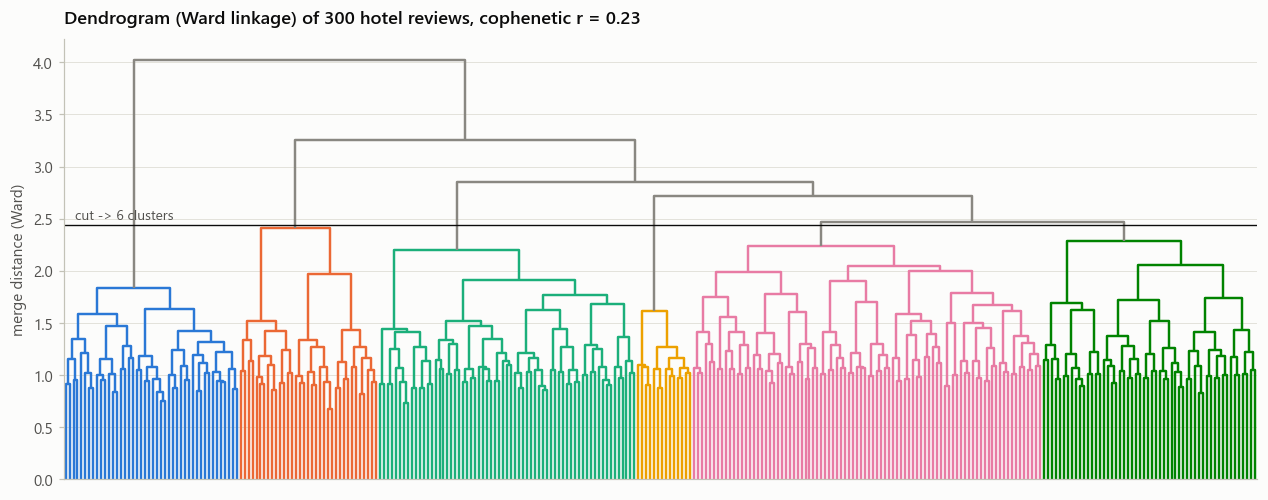

In [8]:
d, Z = KM["hotel"]["d"], REP["hotel"]["Z"]
k_hot = KM["hotel"]["metrics"]["K"]
per = 300 // k_hot
samp = np.concatenate([np.random.default_rng(SEED).choice(np.where(d["cluster"].values == c)[0], per, replace=False)
                       for c in range(k_hot)])
Zs = Z[samp].astype(np.float64)
L = linkage(Zs, method="ward")
coph, _ = cophenet(L, pdist(Zs))
heights = L[:, 2]
n = len(Zs)
life = pd.Series({K: heights[n - K] - heights[n - K - 1] for K in range(2, 13)}, name="lifetime")
hc = fcluster(L, t=k_hot, criterion="maxclust")
ari = adjusted_rand_score(d["cluster"].values[samp], hc)
print(f"cophenetic correlation = {coph:.3f}; K-cluster lifetimes (longest = most natural K):")
print(life.round(4).to_string())
print(f"longest lifetime at K = {life.idxmax()};  ARI(dendrogram cut at K={k_hot}, k-means) = {ari:.3f}")
print(pd.crosstab(pd.Series(d["cluster"].values[samp], name="k-means"), pd.Series(hc, name="hierarchical")))

fig, ax = plt.subplots(figsize=(14, 5.2))
cut = (heights[n - k_hot] + heights[n - k_hot - 1]) / 2
from scipy.cluster import hierarchy
hierarchy.set_link_color_palette(P.SERIES[:8])
dendrogram(L, ax=ax, no_labels=True, color_threshold=cut, above_threshold_color=P.MUTED)
ax.axhline(cut, color=P.INK, lw=0.9)
ax.annotate(f"cut -> {k_hot} clusters", xy=(0.01, cut), xycoords=("axes fraction", "data"), xytext=(0, 4),
            textcoords="offset points", fontsize=9, color=P.INK2)
ax.set_title(f"Dendrogram (Ward linkage) of 300 hotel reviews, cophenetic r = {coph:.2f}")
ax.set_ylabel("merge distance (Ward)")
ax.grid(axis="x", visible=False)
P.save(fig, "k04_dendrogram")
plt.show()

**Inferences (dendrogram)**
* The **first split of the tree isolates the Las Vegas reviews** (43 of the 50 sampled k-means
  cluster-0 reviews form one branch). Their casino and strip vocabulary makes them the most
  distinct group, so the K-cluster lifetime rule favours **K = 2** (lifetime 0.77). K = 6
  has a short lifetime: below the top split the structure is gradual, not sharp.
* The dendrogram cut at K = 6 agrees **moderately** with k-means (ARI = 0.32). Las Vegas,
  San Francisco, generic praise and complaints are each recovered by both methods (34–43 of
  50). New York and London are split differently, because their reviews share most of their
  vocabulary.
* The cophenetic correlation is low (0.23): a tree distorts distances in 100-dimensional text
  space. Hierarchical clustering is therefore useful here to *see* the merge structure on a
  sample, while k-means is the scalable method for all 218k reviews.

## Save the clustering outputs (and the LSA features for the PySpark comparison)

In [9]:
for dom in REP:
    KM[dom]["prof"].to_csv(TABLES / f"kmeans_profile_{dom}.csv")
    SEL[dom].to_csv(TABLES / f"kmeans_selection_{dom}.csv")
feat = pd.DataFrame({"features": list(REP["hotel"]["Z"].astype(np.float64))})
feat.to_parquet(CLEAN / "lsa_hotel.parquet", index=False)
print("saved LSA features:", feat.shape, "->", CLEAN / "lsa_hotel.parquet")
pd.DataFrame([KM[d]["metrics"] for d in KM], index=list(KM)).round(4)

saved LSA features: (218298, 1) -> C:\data\ASBD_exam\clean\lsa_hotel.parquet


,K,SSE,silhouette,davies_bouldin,calinski_harabasz,seconds
hotel,6,160112.5781,0.0300,4.9871,175.8827,18.4303
car,7,31980.6621,0.0261,5.2774,139.9477,9.3994
